In [1]:
import os
import glob
import kagglehub
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler, LabelEncoder
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)

In [2]:
dataset_path = kagglehub.dataset_download(
    "jaceprater/smokers-health-data"
)

print("Indirilen klasor:", dataset_path)

csv_files = glob.glob(
    os.path.join(dataset_path, "**", "*.csv"),
    recursive=True
)

if not csv_files:
    raise FileNotFoundError(
        "Veri seti klasorunde CSV dosyasi bulunamadi."
    )

print("\nBulunan CSV dosyalari:")
for i, file in enumerate(csv_files):
    print(i, os.path.basename(file))


100%|██████████| 29.4k/29.4k [00:00<00:00, 5.94MB/s]

Extracting files...
Indirilen klasor: /root/.cache/kagglehub/datasets/jaceprater/smokers-health-data/versions/1

Bulunan CSV dosyalari:
0 smoking_health_data_final.csv


In [3]:
df = pd.read_csv(csv_files[0])

print("\nIlk 5 satir:")
print(df.head())

print("\nVeri boyutu:", df.shape)
print("\nSutun isimleri:")
print(df.columns.tolist())

print("\nVeri tipleri:")
print(df.dtypes)

print("\nEksik deger sayilari:")
print(df.isnull().sum())

print("\nIstatistiksel ozet:")
print(df.describe(include="all").T)



Ilk 5 satir:
   age   sex current_smoker  heart_rate blood_pressure  cigs_per_day   chol
0   54  male            yes          95         110/72           NaN  219.0
1   45  male            yes          64         121/72           NaN  248.0
2   58  male            yes          81       127.5/76           NaN  235.0
3   42  male            yes          90       122.5/80           NaN  225.0
4   42  male            yes          62         119/80           NaN  226.0

Veri boyutu: (3900, 7)

Sutun isimleri:
['age', 'sex', 'current_smoker', 'heart_rate', 'blood_pressure', 'cigs_per_day', 'chol']

Veri tipleri:
age                 int64
sex                object
current_smoker     object
heart_rate          int64
blood_pressure     object
cigs_per_day      float64
chol              float64
dtype: object

Eksik deger sayilari:
age                0
sex                0
current_smoker     0
heart_rate         0
blood_pressure     0
cigs_per_day      14
chol               7
dtype: int64

Istat

In [19]:
target_candidates = [
    "current_smoker",

]

column_map = {
    str(col).strip().lower().replace(" ", "_"): col
    for col in df.columns
}

target = None

for candidate in target_candidates:
    if candidate in column_map:
        target = column_map[candidate]
        break

if target is None:
    raise ValueError(
        "Sigara kullanimi hedef sutunu otomatik bulunamadi. "
        "Yukaridaki sutun listesini kontrol edip target "
        "degiskenini veri setindeki uygun sutunla degistir."
    )

print("\nHedef degisken:", target)

# Hedef degeri eksik olan satirlari kaldir
df = df.dropna(subset=[target]).copy()

# Hedef degiskenin sinif dagilimi
print("\nHedef sinif dagilimi:")
print(df[target].value_counts())



Hedef degisken: current_smoker

Hedef sinif dagilimi:
current_smoker
no     1968
yes    1932
Name: count, dtype: int64


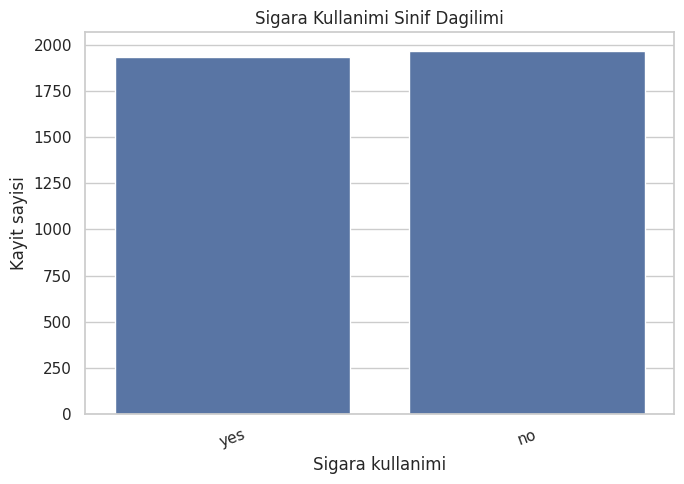

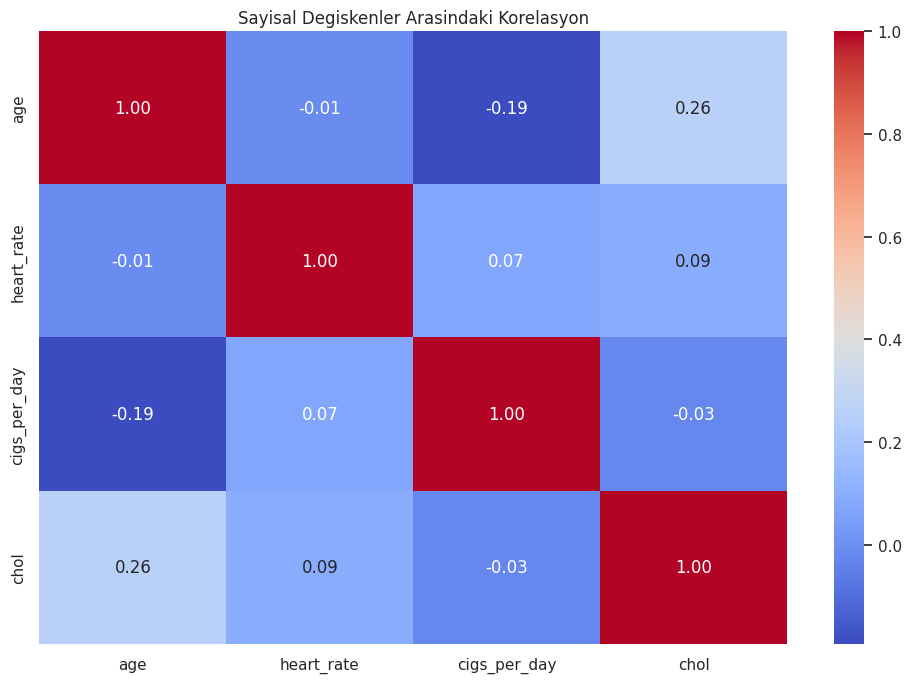

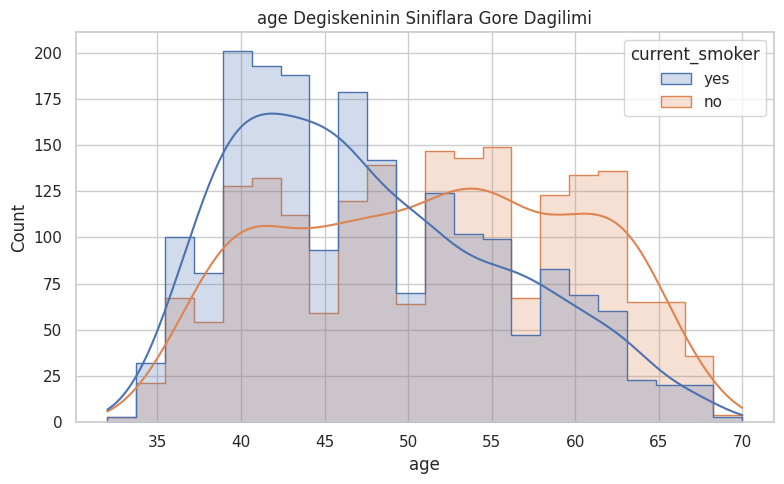

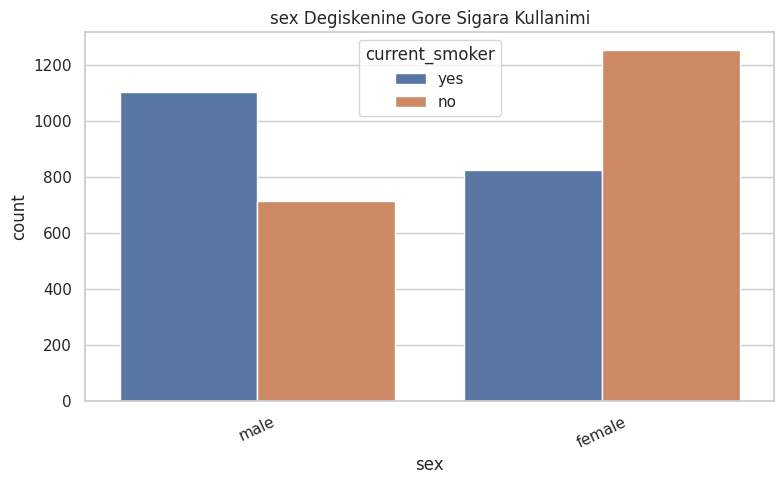

In [7]:


sns.set_theme(style="whitegrid")

# Grafik 1: Hedef sinif dagilimi
plt.figure(figsize=(7, 5))
sns.countplot(data=df, x=target)
plt.title("Sigara Kullanimi Sinif Dagilimi")
plt.xlabel("Sigara kullanimi")
plt.ylabel("Kayit sayisi")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

# Grafik 2: Sayisal degiskenlerin korelasyonu
numeric_df = df.select_dtypes(include=np.number)

if numeric_df.shape[1] >= 2:
    plt.figure(figsize=(10, 7))
    sns.heatmap(
        numeric_df.corr(),
        annot=True,
        cmap="coolwarm",
        fmt=".2f"
    )
    plt.title("Sayisal Degiskenler Arasindaki Korelasyon")
    plt.tight_layout()
    plt.show()
else:
    print("Korelasyon grafigi icin yeterli sayisal sutun yok.")

# Grafik 3: Sayisal degiskenlerin dagilimi
numeric_features = [
    col for col in numeric_df.columns if col != target
]

if numeric_features:
    selected_feature = numeric_features[0]

    plt.figure(figsize=(8, 5))
    sns.histplot(
        data=df,
        x=selected_feature,
        hue=target,
        kde=True,
        element="step"
    )
    plt.title(
        selected_feature + " Degiskeninin Siniflara Gore Dagilimi"
    )
    plt.tight_layout()
    plt.show()

# Grafik 4: Kategorik degisken varsa siniflarla iliskisi
categorical_features = df.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

categorical_features = [
    col for col in categorical_features if col != target
]

if categorical_features:
    cat_feature = categorical_features[0]

    plt.figure(figsize=(8, 5))
    sns.countplot(
        data=df,
        x=cat_feature,
        hue=target
    )
    plt.title(
        cat_feature + " Degiskenine Gore Sigara Kullanimi"
    )
    plt.xticks(rotation=25)
    plt.tight_layout()
    plt.show()

In [8]:
# Hedef degisken X'e dahil edilmez.
X = df.drop(columns=[target]).copy()
y = df[target].copy()

# Tahmin icin yararsiz olabilecek tamamen bos sutunlari kaldir
X = X.dropna(axis=1, how="all")

# Etiketleri sayisal hale getir
label_encoder = LabelEncoder()
y = label_encoder.fit_transform(y.astype(str))

print("\nHedef sinif kodlari:")
for i, name in enumerate(label_encoder.classes_):
    print(name, "=", i)

# Sayisal ve kategorik sutunlari ayir
numeric_columns = X.select_dtypes(
    include=np.number
).columns.tolist()

categorical_columns = X.select_dtypes(
    exclude=np.number
).columns.tolist()

# Sayisal veriler: eksikleri medyanla doldur, olceklendir
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Kategorik veriler: eksikleri en sik degerle doldur,
# sonra One-Hot Encoding uygula
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_columns),
    ("categorical", categorical_pipeline, categorical_columns)
])

# Siniflar uygunsa stratify ile dagilim korunur.
class_counts = pd.Series(y).value_counts()
stratify_y = y if class_counts.min() >= 2 else None

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=stratify_y
)

print("\nEgitim veri boyutu:", X_train.shape)
print("Test veri boyutu:", X_test.shape)



Hedef sinif kodlari:
no = 0
yes = 1

Egitim veri boyutu: (3120, 6)
Test veri boyutu: (780, 6)


In [9]:
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        class_weight="balanced",
        random_state=42
    )
}

results = []
trained_models = {}
predictions = {}

for model_name, model in models.items():

    # On isleme ve model tek Pipeline icinde
    pipeline = Pipeline([
        ("preprocessing", preprocessor),
        ("model", model)
    ])

    pipeline.fit(X_train, y_train)

    y_pred = pipeline.predict(X_test)

    trained_models[model_name] = pipeline
    predictions[model_name] = y_pred

    results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(
            y_test, y_pred, average="weighted", zero_division=0
        ),
        "Recall": recall_score(
            y_test, y_pred, average="weighted", zero_division=0
        ),
        "F1 Score": f1_score(
            y_test, y_pred, average="weighted", zero_division=0
        )
    })



Model karsilastirma tablosu:
              Model  Accuracy  Precision  Recall  F1 Score
Logistic Regression    0.9808     0.9815  0.9808    0.9808
      Random Forest    0.9949     0.9949  0.9949    0.9949


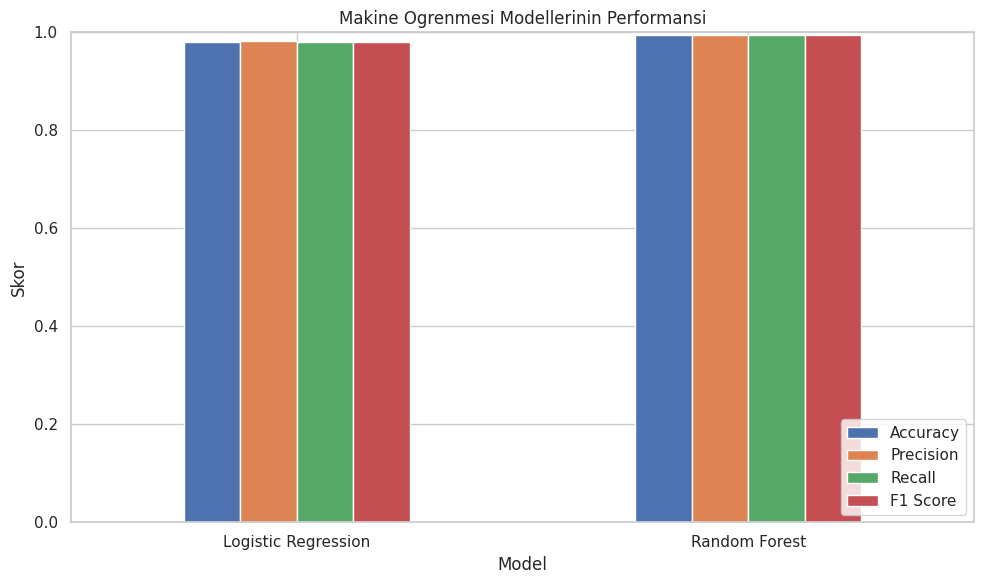

In [10]:

results_df = pd.DataFrame(results)

print("\nModel karsilastirma tablosu:")
print(results_df.round(4).to_string(index=False))

# Grafik 5: Model metrikleri
results_plot = results_df.set_index("Model")[
    ["Accuracy", "Precision", "Recall", "F1 Score"]
]

results_plot.plot(
    kind="bar",
    figsize=(10, 6),
    ylim=(0, 1)
)

plt.title("Makine Ogrenmesi Modellerinin Performansi")
plt.ylabel("Skor")
plt.xlabel("Model")
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()



MODEL: Logistic Regression
              precision    recall  f1-score   support

          no       0.96      1.00      0.98       394
         yes       1.00      0.96      0.98       386

    accuracy                           0.98       780
   macro avg       0.98      0.98      0.98       780
weighted avg       0.98      0.98      0.98       780



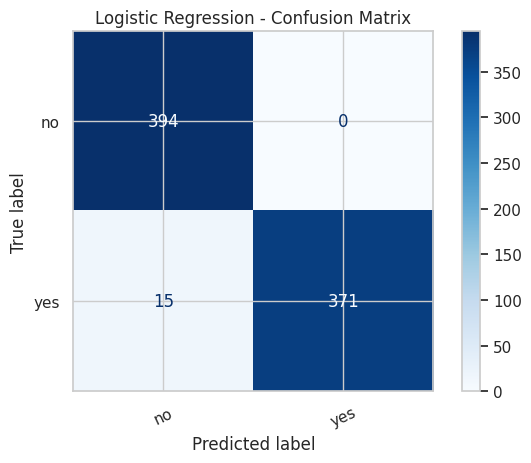


MODEL: Random Forest
              precision    recall  f1-score   support

          no       0.99      1.00      0.99       394
         yes       1.00      0.99      0.99       386

    accuracy                           0.99       780
   macro avg       0.99      0.99      0.99       780
weighted avg       0.99      0.99      0.99       780



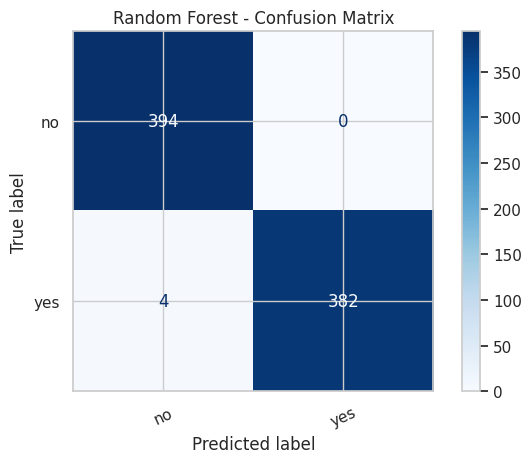

In [11]:

for model_name, y_pred in predictions.items():

    print("\n", "=" * 50)
    print("MODEL:", model_name)
    print("=" * 50)

    print(
        classification_report(
            y_test,
            y_pred,
            labels=np.arange(len(label_encoder.classes_)),
            target_names=label_encoder.classes_,
            zero_division=0
        )
    )

    cm = confusion_matrix(
        y_test,
        y_pred,
        labels=np.arange(len(label_encoder.classes_))
    )

    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=label_encoder.classes_
    )

    disp.plot(cmap="Blues", values_format="d")
    plt.title(model_name + " - Confusion Matrix")
    plt.xticks(rotation=25)
    plt.tight_layout()
    plt.show()
